# 2. What is every cohort's curve on 60,000 members, and what is the blend made of?

**Week 4, Thursday. Chapter 2 of 3.** This notebook does chapter 1's hand count on the full data
and reproduces the dashboard's blended number as a weighted average of cohort rates. The pivot is
one line; the decomposition is one more.

**Who needs the answer.** The head of Gold, who needs the number the dashboard misses.

**The questions on the way.** How is a cohort table built, what does the triangle look like at
scale, how does the blend decompose into size times rate.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
import csv, pathlib
from collections import Counter

DATA = pathlib.Path("../data")
members = pd.read_csv(DATA / "C2_W04_D04_members_STUDENT.csv")
member_months = pd.read_csv(DATA / "C2_W04_D04_member_months_STUDENT.csv")
events = pd.read_csv(DATA / "C2_W04_D04_events_STUDENT.csv")
twelve = pd.read_csv(DATA / "C2_W04_D04_twelve_rows_STUDENT.csv")

PASS_COUNT = {"pass": 0, "fail": 0}


def check(label, condition, detail=""):
    ok = bool(condition)
    PASS_COUNT["pass" if ok else "fail"] += 1
    word = "PASS" if ok else "FAIL"
    print(f"{word}  {label}" + (f"  ({detail})" if detail else ""))
    return ok


def check_summary():
    print(f"\n{'PASS' if PASS_COUNT['fail'] == 0 else 'FAIL'}  "
          f"{PASS_COUNT['pass']} checks passed and {PASS_COUNT['fail']} failed in this notebook.")


print(f"loaded: {len(members)} members, {len(member_months)} member-months, "
      f"{len(events)} events, {len(twelve)} twelve-row members")

loaded: 60000 members, 248000 member-months, 225076 events, 12 twelve-row members


## What does the members table hold?

Each row is one member with her signup date, the cohort month that signup falls into, the signup
channel and her Chennai zone. Nine cohorts span January to September 2026. September is still
unfolding, so its month-one reading is not in this notebook.

In [2]:
print(members.head(6).to_string(index=False))
print()
print("rows:", len(members))
print()
print("cohort sizes:")
print(members["cohort_month"].value_counts().sort_index())
check("members has 60000 rows", len(members) == 60000, detail=f"actual {len(members)}")
check("August cohort is 13000", (members["cohort_month"] == "2026-08").sum() == 13000)

member_id signup_date cohort_month signup_channel    zone
 ZG000001  2026-01-18      2026-01        organic    west
 ZG000002  2026-01-15      2026-01        organic   north
 ZG000003  2026-01-23      2026-01        organic central
 ZG000004  2026-01-26      2026-01        organic    west
 ZG000005  2026-01-05      2026-01        organic   south
 ZG000006  2026-01-29      2026-01        organic    west

rows: 60000

cohort sizes:
cohort_month
2026-01     5000
2026-02     5000
2026-03     5000
2026-04     5000
2026-05     5000
2026-06     5000
2026-07     5000
2026-08    13000
2026-09    12000
Name: count, dtype: int64
PASS  members has 60000 rows  (actual 60000)
PASS  August cohort is 13000


True

## The cohort sizes drawn as a bar

Jan to July are five thousand each, August is thirteen thousand (the sale week), September is
twelve thousand and still growing. The eye reads the August spike at a glance.

/tmp/ipykernel_7069/3211211282.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(sizes.index.astype(str), rotation=25, ha="right",


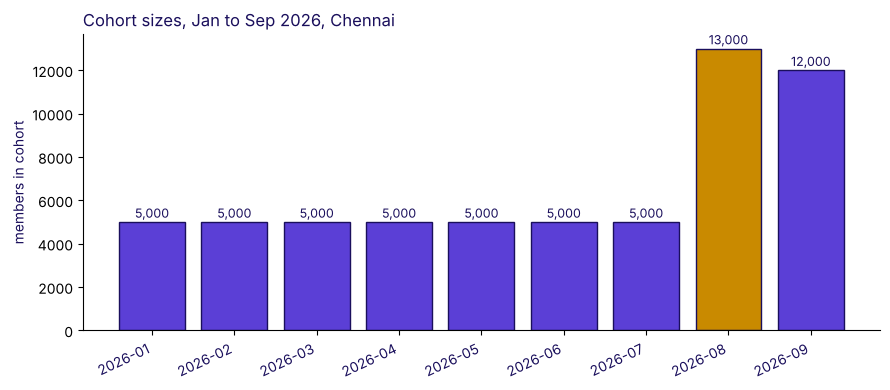

PASS  August is the largest cohort


True

In [3]:
import matplotlib.pyplot as plt

sizes = members["cohort_month"].value_counts().sort_index()
colours = ["#5B3FD6" if c != "2026-08" else "#C98A00" for c in sizes.index]
fig, ax = plt.subplots(figsize=(9, 4.0))
ax.bar(sizes.index.astype(str), sizes.values, color=colours, edgecolor="#1A0F5C")
for i, v in enumerate(sizes.values):
    ax.text(i, v + 200, f"{v:,}", ha="center", color="#1A0F5C", fontsize=9)
ax.set_xticklabels(sizes.index.astype(str), rotation=25, ha="right",
                   color="#1A0F5C", fontsize=10)
ax.set_ylabel("members in cohort", color="#1A0F5C")
ax.set_title("Cohort sizes, Jan to Sep 2026, Chennai", loc="left", color="#1A0F5C")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
check("August is the largest cohort",
      sizes.loc["2026-08"] == sizes.max())

## What does one pivot_table turn member_months into?

The member_months table has one row per member per calendar month since signup, with an orders
flag of 0 or 1. A pivot_table averaged by cohort month and months-since-signup gives the
retention triangle on all 60,000 members. Each cell is the share of that cohort who ordered
that many months later.

In [4]:
triangle = (member_months
            .assign(cohort=lambda d: d["member_id"].map(members.set_index("member_id")["cohort_month"]))
            .query("months_since_signup >= 1")
            .pivot_table(index="cohort", columns="months_since_signup",
                         values="orders", aggfunc="mean")
            .round(3))
print(triangle)
check("triangle has eight cohort rows with observed month-one, Jan to August",
      len(triangle) == 8)
check("January row's month-one retention is near 0.58",
      abs(triangle.loc["2026-01", 1] - 0.58) < 0.03,
      detail=f"actual {triangle.loc['2026-01', 1]:.3f}")
check("August row's month-one retention is near 0.31",
      abs(triangle.loc["2026-08", 1] - 0.31) < 0.03,
      detail=f"actual {triangle.loc['2026-08', 1]:.3f}")

months_since_signup      1      2      3      4      5      6      7      8
cohort                                                                     
2026-01              0.579  0.434  0.382  0.373  0.372  0.362  0.372  0.367
2026-02              0.564  0.411  0.371  0.366  0.363  0.375  0.367    NaN
2026-03              0.552  0.408  0.372  0.372  0.379  0.369    NaN    NaN
2026-04              0.533  0.380  0.376  0.364  0.367    NaN    NaN    NaN
2026-05              0.514  0.372  0.367  0.370    NaN    NaN    NaN    NaN
2026-06              0.501  0.375  0.352    NaN    NaN    NaN    NaN    NaN
2026-07              0.500  0.369    NaN    NaN    NaN    NaN    NaN    NaN
2026-08              0.303    NaN    NaN    NaN    NaN    NaN    NaN    NaN
PASS  triangle has eight cohort rows with observed month-one, Jan to August
PASS  January row's month-one retention is near 0.58  (actual 0.579)
PASS  August row's month-one retention is near 0.31  (actual 0.303)


True

## Does every cohort fall across its own observed ages?

For each cohort with at least two observed ages, the month-two rate should be below the
month-one rate. The teaching claim is that each row drops left to right; the check confirms it.

In [5]:
drops = []
for cohort, row in triangle.iterrows():
    row = row.dropna()
    if len(row) >= 2:
        drops.append((cohort, float(row.iloc[0]), float(row.iloc[1])))
for c, m1, m2 in drops:
    print(f"{c}: m1 {m1:.3f}, m2 {m2:.3f}, change {m2 - m1:+.3f}")
check("every cohort with two observed ages falls from m1 to m2",
      all(m2 < m1 for c, m1, m2 in drops),
      detail=f"{sum(1 for c, m1, m2 in drops if m2 < m1)} of {len(drops)} fall")

2026-01: m1 0.579, m2 0.434, change -0.145
2026-02: m1 0.564, m2 0.411, change -0.153
2026-03: m1 0.552, m2 0.408, change -0.144
2026-04: m1 0.533, m2 0.380, change -0.153
2026-05: m1 0.514, m2 0.372, change -0.142
2026-06: m1 0.501, m2 0.375, change -0.126
2026-07: m1 0.500, m2 0.369, change -0.131
PASS  every cohort with two observed ages falls from m1 to m2  (7 of 7 fall)


True

## What does the triangle look like as a picture?

A heatmap, cohort on the row and age on the column, is the picture the deck carries. Draw it
here with matplotlib, from the triangle you just computed, so the notebook's own output matches
the deck's.

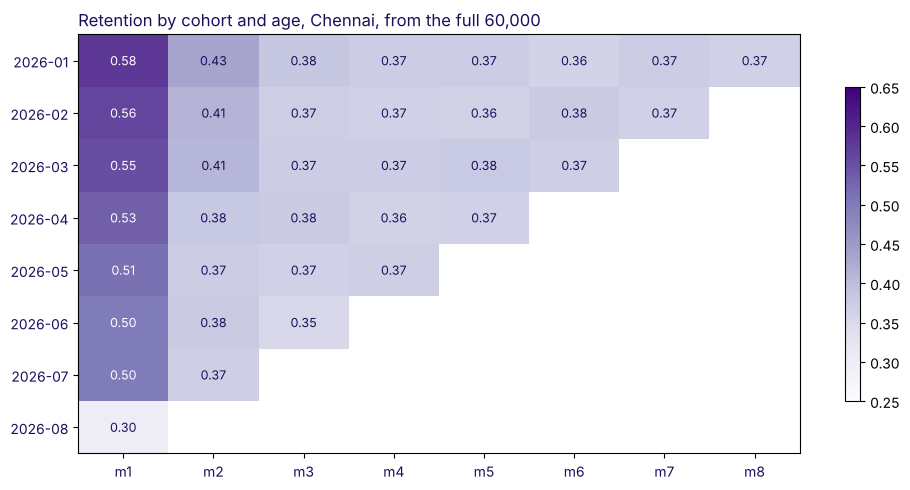

PASS  the triangle picture drew eight rows


True

In [6]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(10, 5.0))
im = ax.imshow(triangle.values, cmap="Purples", vmin=0.25, vmax=0.65, aspect="auto")
for i in range(triangle.shape[0]):
    for j in range(triangle.shape[1]):
        v = triangle.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if v > 0.44 else "#1A0F5C", fontsize=9)
ax.set_xticks(range(triangle.shape[1]))
ax.set_xticklabels([f"m{k}" for k in triangle.columns], color="#1A0F5C")
ax.set_yticks(range(triangle.shape[0]))
ax.set_yticklabels(triangle.index, color="#1A0F5C")
ax.set_title("Retention by cohort and age, Chennai, from the full 60,000", loc="left",
             color="#1A0F5C")
plt.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout()
plt.show()
check("the triangle picture drew eight rows", triangle.shape[0] == 8)

## What is the blended retention for June to September, straight from the data?

The dashboard's blended number is: for each reporting month, the share of members who signed up
before that month who placed at least one order in it. The direct count is one filter and one
mean. The next cell reproduces every reporting month's blend from the member tables.

**Predict before you run.** The ticket says 38 percent, flat. The computed values will be close
but not exact. Where would you expect the biggest gap: June, July, August or September?

In [7]:
def blended(month):
    pre = members[members["cohort_month"] < month]["member_id"]
    active = member_months[(member_months["month"] == month)
                           & (member_months["orders"] == 1)
                           & (member_months["member_id"].isin(pre))]
    return len(active) / len(pre) if len(pre) else 0.0

for month in ["2026-06", "2026-07", "2026-08", "2026-09"]:
    b = blended(month)
    print(f"{month}: blended retention {b:.3f}")
check("June blended retention is in [0.33, 0.44]",
      0.33 <= blended("2026-06") <= 0.44, detail=f"{blended('2026-06'):.3f}")
check("September blended retention is in [0.33, 0.44]",
      0.33 <= blended("2026-09") <= 0.44, detail=f"{blended('2026-09'):.3f}")

2026-06: blended retention 0.401
2026-07: blended retention 0.391
2026-08: blended retention 0.390
2026-09: blended retention 0.349


PASS  June blended retention is in [0.33, 0.44]  (0.401)
PASS  September blended retention is in [0.33, 0.44]  (0.349)


True

## The blended retention beside each cohort's month-one, in one picture

The dashboard line (amber) drifts a few points across the four reporting months. The cohort
month-one points (purple) step down every month. Both drawn on the same axis: the dashboard
sits above each new cohort's own m1 by a lot, because the mix averages old cohorts' floors with
the newest cohort's low m1.

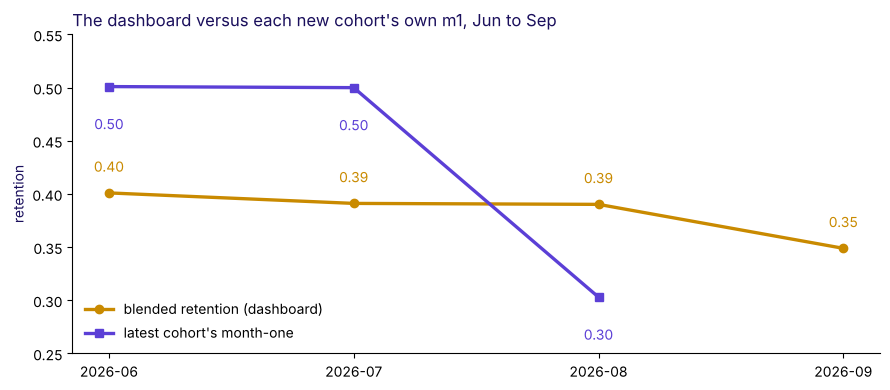

PASS  the amber line has four points


True

In [8]:
import matplotlib.pyplot as plt

report_months = ["2026-06", "2026-07", "2026-08", "2026-09"]
dash = [blended(m) for m in report_months]
# the cohort whose m1 corresponds to each reporting month (the one that just entered)
latest_m1 = [triangle.loc[m, 1] if m in triangle.index else float("nan") for m in report_months]

fig, ax = plt.subplots(figsize=(9, 4.0))
ax.plot(report_months, dash, color="#C98A00", lw=2.4, marker="o",
        label="blended retention (dashboard)")
ax.plot(report_months, latest_m1, color="#5B3FD6", lw=2.4, marker="s",
        label="latest cohort's month-one")
for i, (d, m1) in enumerate(zip(dash, latest_m1)):
    ax.text(i, d + 0.02, f"{d:.2f}", color="#C98A00", ha="center", fontsize=10)
    if m1 == m1:  # not NaN
        ax.text(i, m1 - 0.04, f"{m1:.2f}", color="#5B3FD6", ha="center", fontsize=10)
ax.set_ylim(0.25, 0.55)
ax.set_ylabel("retention", color="#1A0F5C")
ax.legend(loc="lower left", frameon=False)
ax.set_title("The dashboard versus each new cohort's own m1, Jun to Sep",
             loc="left", color="#1A0F5C")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
check("the amber line has four points", len(dash) == 4)

## Is the blended rate equal to the weighted average of cohort rates?

For September, pre-signed members span the Jan to Aug cohorts. The weighted average formula
should return the same number as the direct count. The two computations are a second route to
the same answer; if they agree, the decomposition is correct.

In [9]:
month = "2026-09"
pre_cohorts = [c for c in triangle.index if c < month]
total_size = 0
weighted = 0.0
rows = []
for c in pre_cohorts:
    size = int((members["cohort_month"] == c).sum())
    k = (int(month[:4]) - int(c[:4])) * 12 + (int(month[5:7]) - int(c[5:7]))
    rate = triangle.loc[c, k] if k in triangle.columns and not pd.isna(triangle.loc[c, k]) else 0
    weighted += size * rate
    total_size += size
    rows.append((c, k, size, float(rate)))
w_avg = weighted / total_size
direct = blended(month)
for c, k, size, rate in rows:
    print(f"cohort {c}, age m{k}, size {size:>5}, rate {rate:.3f}")
print()
print(f"weighted average: {w_avg:.3f}")
print(f"direct count:     {direct:.3f}")
check("weighted average equals the direct count to three decimals",
      abs(w_avg - direct) < 0.002,
      detail=f"weighted {w_avg:.4f} vs direct {direct:.4f}")

cohort 2026-01, age m8, size  5000, rate 0.367
cohort 2026-02, age m7, size  5000, rate 0.367
cohort 2026-03, age m6, size  5000, rate 0.369
cohort 2026-04, age m5, size  5000, rate 0.367
cohort 2026-05, age m4, size  5000, rate 0.370
cohort 2026-06, age m3, size  5000, rate 0.352
cohort 2026-07, age m2, size  5000, rate 0.369
cohort 2026-08, age m1, size 13000, rate 0.303

weighted average: 0.349
direct count:     0.349
PASS  weighted average equals the direct count to three decimals  (weighted 0.3488 vs direct 0.3489)


True

## Your turn: which cohort pulls the September blend down the most?

Think about the stacked bars in the deck: the August cohort is the biggest row at the youngest
age, and its month-one rate is the lowest in the table. In the empty cell below, write code to
find the cohort whose contribution (size times rate) is the lowest fraction of the blend at
September. The deck will not name it until the TA lab; the data is the authoritative read.

## What did the chapter answer?

The dashboard's 38 is a weighted average of eight cohort rates at eight different ages. Every
cohort falls across its own ages, the August cohort is the biggest and lowest in September, and
the direct count equals the weighted average to three decimals. The next notebook moves from the
cohort table to the funnel: once the entry moment is fixed, which stage owns the loss, in which
unit, after which date.

In [10]:
check_summary()


PASS  12 checks passed and 0 failed in this notebook.
